# Лабораторная 3. Разметка и аугментация данных

**Датасет:** [racoon-detection (Kaggle)](https://www.kaggle.com/datasets/debasisdotcom/racoon-detection)

1. Разметить датасет
2. Сделать аугментацию для детекции объектов

In [1]:
!pip install -q albumentations==1.4.3

In [10]:
import os, zipfile, random
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import albumentations as A

with zipfile.ZipFile("data/racoon.zip") as z:
    z.extractall("racoon_data")

IMAGES_DIR = "racoon_data/Racoon Images/images"
df = pd.read_csv("racoon_data/train_labels_.csv")
df.head()

,filename,width,height,class,xmin,ymin,xmax,ymax
0,raccoon-17.jpg,259,194,raccoon,95,60,167,118
1,raccoon-11.jpg,660,432,raccoon,3,1,461,431
2,raccoon-63.jpg,600,400,raccoon,74,107,280,290
3,raccoon-63.jpg,600,400,raccoon,227,93,403,298
4,raccoon-60.jpg,273,185,raccoon,58,33,197,127


## Разметка: группировка боксов по изображениям

In [11]:
class_to_id = {"raccoon": 0}

samples = [
    {
        "filename": fn,
        "filepath": os.path.join(IMAGES_DIR, fn),
        "boxes": g[["xmin", "ymin", "xmax", "ymax"]].values.tolist(),
        "labels": g["class"].map(class_to_id).tolist(),
    }
    for fn, g in df.groupby("filename")
]

multi = [i for i, s in enumerate(samples) if len(s["boxes"]) > 1]
print("Изображений:", len(samples), "| с несколькими енотами:", len(multi), multi[:10])

Изображений: 160 | с несколькими енотами: 12 [17, 19, 20, 27, 39, 66, 83, 91, 96, 119]


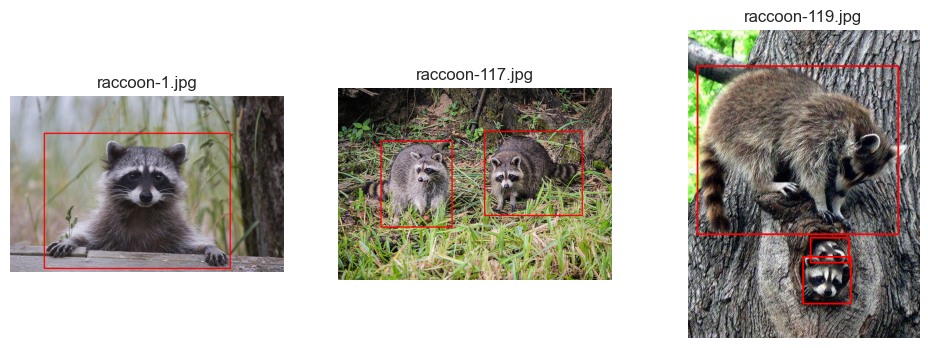

In [7]:
def load(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

def draw(img, boxes, color=(255, 0, 0)):
    img = img.copy()
    for x1, y1, x2, y2 in boxes:
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
    return img

def show(images, titles):
    plt.figure(figsize=(4 * len(images), 4))
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(1, len(images), i); plt.imshow(im); plt.title(t); plt.axis("off")
    plt.show()

ids = [0, 17, 19]
show([draw(load(samples[i]["filepath"]), samples[i]["boxes"]) for i in ids],
     [samples[i]["filename"] for i in ids])

## Аугментация для детекции объектов

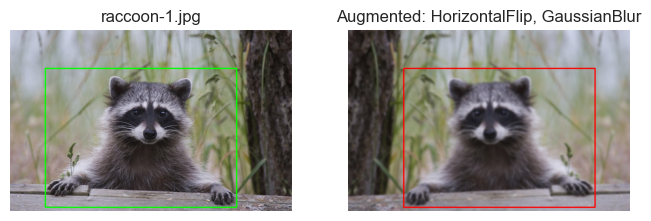

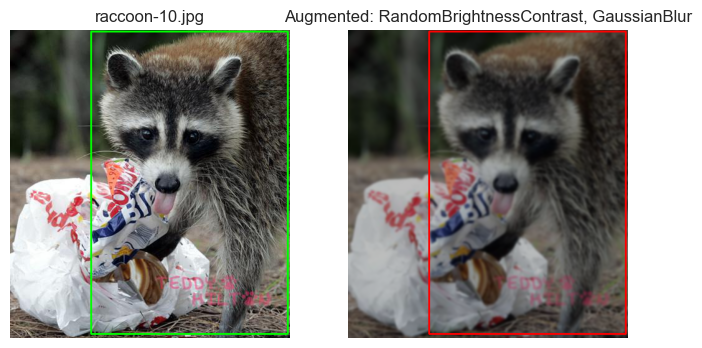

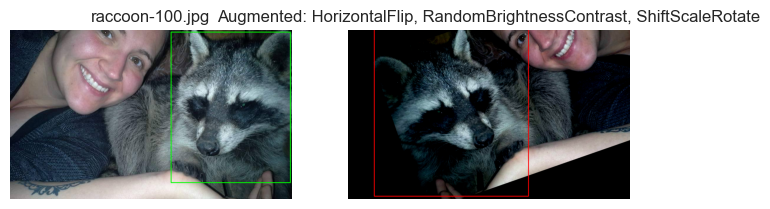

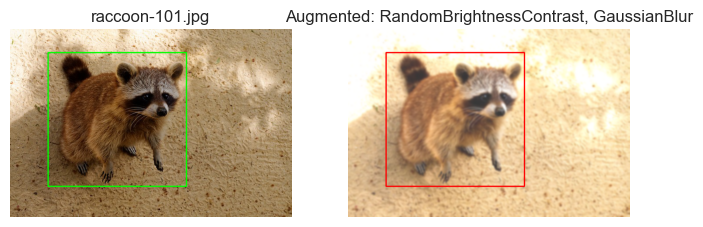

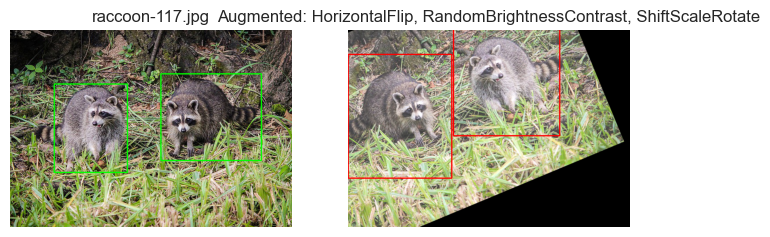

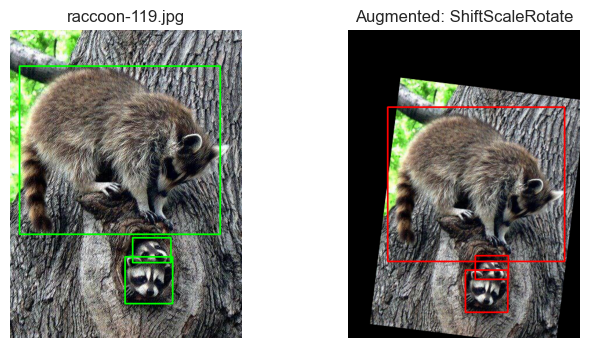

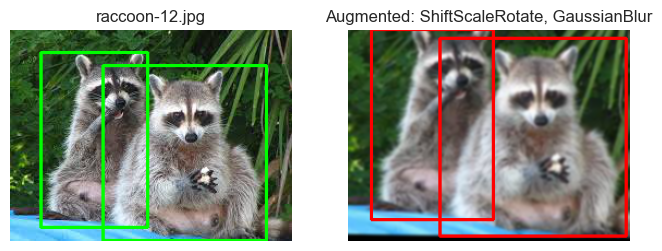

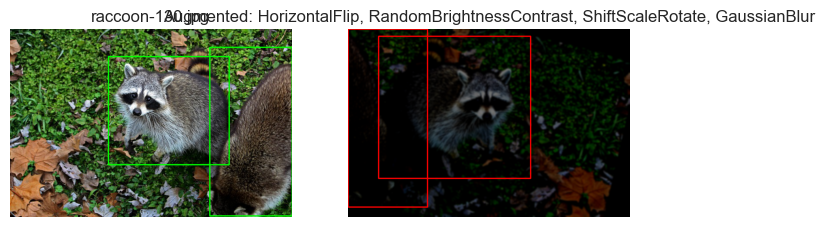

In [8]:
transform = A.ReplayCompose(
    [
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.7),
        A.ShiftScaleRotate(shift_limit=0.15, scale_limit=0.2, rotate_limit=25,
                           border_mode=cv2.BORDER_CONSTANT, value=0, p=0.8),
        A.GaussianBlur(blur_limit=(5, 9), p=0.4),
    ],
    bbox_params=A.BboxParams(format="pascal_voc", label_fields=["class_labels"], min_visibility=0.3),
)

def augment(s):
    img = load(s["filepath"])
    return img, transform(image=img, bboxes=s["boxes"], class_labels=s["labels"])

def applied_names(aug):
    return [t["__class_fullname__"].split(".")[-1] for t in aug["replay"]["transforms"] if t["applied"]]

demo_ids = [0, 1, 2, 3] + multi[:4]
for i in demo_ids:
    while True:
        img, aug = augment(samples[i])
        if applied_names(aug):
            break
    show([draw(img, samples[i]["boxes"], (0, 255, 0)), draw(aug["image"], aug["bboxes"])],
         [samples[i]["filename"], "Augmented: " + ", ".join(applied_names(aug))])

## Аугментация всего датасета и сохранение

In [12]:
OUT_DIR, N_AUG = "augmented_data", 3
os.makedirs(f"{OUT_DIR}/images", exist_ok=True)
id_to_class = {v: k for k, v in class_to_id.items()}

rows = []
for s in samples:
    for k in range(N_AUG):
        _, aug = augment(s)
        name = s["filename"].replace(".jpg", f"_aug{k}.jpg")
        cv2.imwrite(f"{OUT_DIR}/images/{name}", cv2.cvtColor(aug["image"], cv2.COLOR_RGB2BGR))
        h, w = aug["image"].shape[:2]
        rows += [[name, w, h, id_to_class[l], *map(int, b)] for b, l in zip(aug["bboxes"], aug["class_labels"])]

df_aug = pd.DataFrame(rows, columns=["filename", "width", "height", "class", "xmin", "ymin", "xmax", "ymax"])
df_aug.to_csv(f"{OUT_DIR}/labels.csv", index=False)
print("Изображений:", df_aug.filename.nunique(), "| боксов:", len(df_aug))
df_aug.head()

Изображений: 480 | боксов: 519


,filename,width,height,class,xmin,ymin,xmax,ymax
0,raccoon-1_aug0.jpg,650,417,raccoon,17,0,528,417
1,raccoon-1_aug1.jpg,650,417,raccoon,218,39,644,366
2,raccoon-1_aug2.jpg,650,417,raccoon,8,28,633,417
3,raccoon-10_aug0.jpg,450,495,raccoon,0,0,400,495
4,raccoon-10_aug1.jpg,450,495,raccoon,0,18,393,495


## Проверка нового датасета

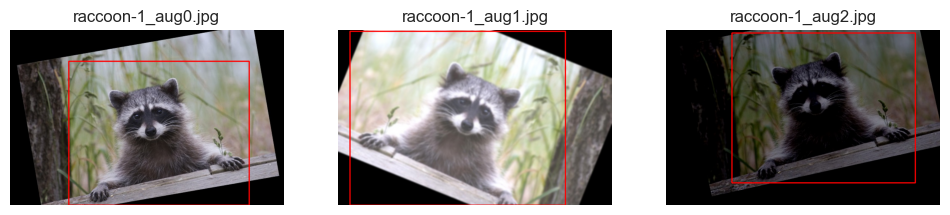

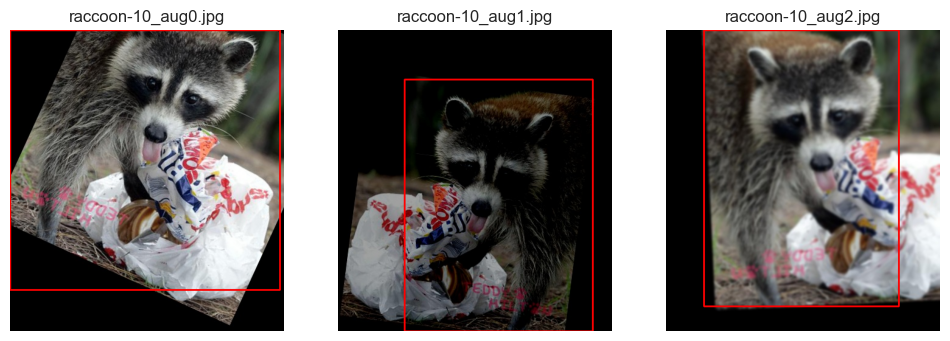

In [7]:
names = df_aug.filename.unique()[:6]
show([draw(load(f"{OUT_DIR}/images/{n}"), df_aug[df_aug.filename == n].iloc[:, 4:].values) for n in names[:3]], names[:3])
show([draw(load(f"{OUT_DIR}/images/{n}"), df_aug[df_aug.filename == n].iloc[:, 4:].values) for n in names[3:]], names[3:])